In [3]:
import pandas as pd

In [4]:
import numpy as np

In [5]:
import matplotlib.pyplot as plt

In [6]:
import seaborn as sns

In [7]:
df = pd.read_csv('titanic/train.csv')

In [8]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [125]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [10]:
df['Survived'].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [11]:
df['Pclass'].value_counts()

Pclass
3    491
1    216
2    184
Name: count, dtype: int64

In [12]:
df['Sex'].value_counts()

Sex
male      577
female    314
Name: count, dtype: int64

In [13]:
df['Age'].value_counts()

Age
24.00    30
22.00    27
18.00    26
28.00    25
19.00    25
         ..
24.50     1
0.67      1
0.42      1
34.50     1
74.00     1
Name: count, Length: 88, dtype: int64

## Hyphothesis One - Survival Rate vs. Passenger Class

In [127]:
df.groupby("Pclass")["Survived"].mean()

Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64

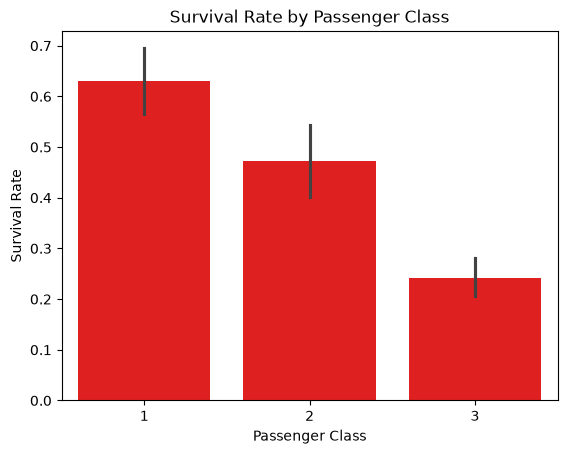

In [45]:
x = df['Pclass']
y = df['Survived']

sns.barplot(x='Pclass', y='Survived', data=df, color='r')
plt.title('Survival Rate by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate')
plt.savefig('Survival Rate by Passenger Class.png')
plt.show()

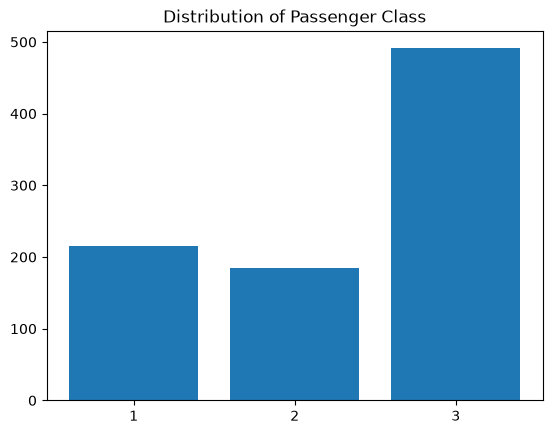

In [67]:
# Number of people in each class
x= ['1','2','3']
y= df['Pclass'].value_counts().sort_index()

plt.bar(x,y)
plt.title('Distribution of Passenger Class')
plt.savefig('Number of people in each class.png')
plt.show()

## Hyphothesis Two - Survival Rate vs. Gender

In [83]:
df.groupby("Sex")["Survived"].value_counts().sort_index()

Sex     Survived
female  0            81
        1           233
male    0           468
        1           109
Name: count, dtype: int64

In [177]:
df.groupby("Sex")["Survived"].mean()

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

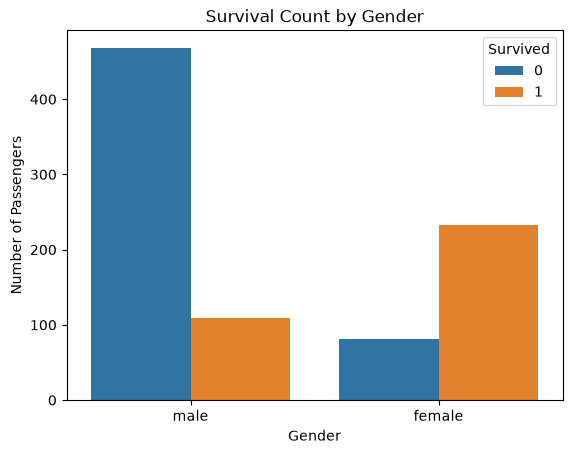

In [131]:
sns.countplot(x="Sex", hue="Survived", data=df)

plt.title("Survival Count by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")
plt.show()

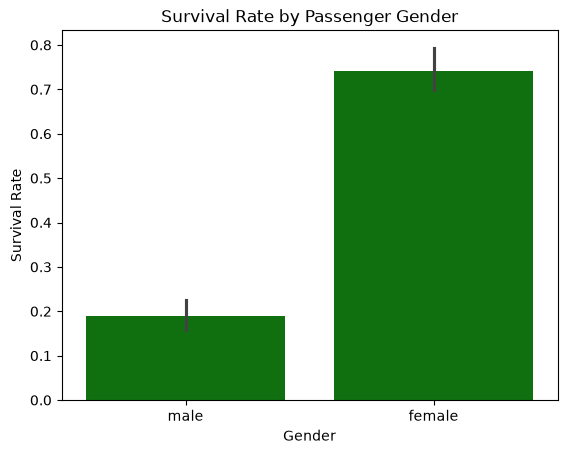

In [133]:
# Number of survived people by gender
sns.barplot(x="Sex", y="Survived", data=df, color='g' )
plt.title('Survival Rate by Passenger Gender')
plt.xlabel("Gender")
plt.ylabel("Survival Rate")
plt.savefig('Number of survived people by gender.png')
plt.show()

## Hyphothesis Three - Survival Rate vs. Age

In [137]:
df.groupby("Survived")["Age"].value_counts().sort_index()

Survived  Age 
0         1.0     2
          2.0     7
          3.0     1
          4.0     3
          6.0     1
                 ..
1         58.0    3
          60.0    2
          62.0    2
          63.0    2
          80.0    1
Name: count, Length: 142, dtype: int64

In [178]:
df.groupby("Survived")["Age"].mean()

Survived
0    30.626179
1    28.343690
Name: Age, dtype: float64

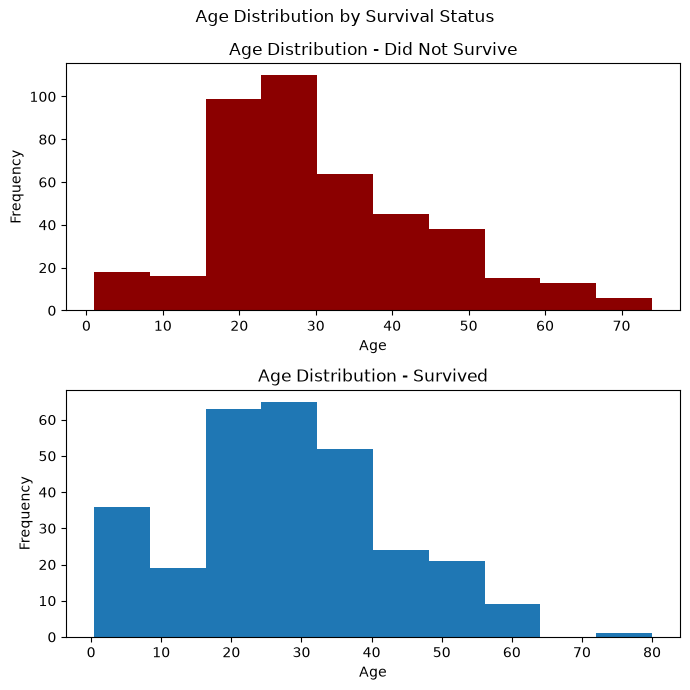

In [176]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 7))

# 1st plot: Did not survive
plt.subplot(2, 1, 1)
plt.hist(df[df["Survived"] == 0]["Age"], bins=10, color='darkred')
plt.title("Age Distribution - Did Not Survive")
plt.xlabel("Age")
plt.ylabel("Frequency")

# 2nd plot: Survived
plt.subplot(2, 1, 2)
plt.hist(df[df["Survived"] == 1]["Age"], bins=10)
plt.title("Age Distribution - Survived")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.suptitle("Age Distribution by Survival Status")
plt.tight_layout()
plt.savefig("Age Distribution by Survival Status.png")
plt.show()

Text(0.5, 1.0, 'Age Distribution by Survival Status')

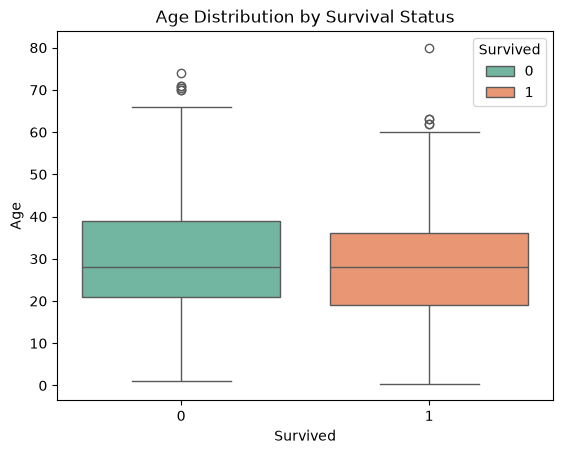

In [162]:
sns.boxplot(x="Survived", y="Age", data=df, hue='Survived', palette="Set2")
plt.title("Age Distribution by Survival Status")